# exp015 — cân bằng lớp mlp

người thực hiện: Phạm Quỳnh Như

ngày: 17/11/2026



## 1. câu hỏi nghiên cứu

RandomOverSampler trên train có cải thiện macro f1 và balanced accuracy so với mlp tuned chưa cân bằng exp010 không?


giữ tham số theo từng outer fold để chỉ khảo sát thay đổi cân bằng lớp

In [6]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display
candidates = [q for p in [Path.cwd(), *Path.cwd().parents] for q in (p, p / 'wesad-stress-detection')]
root = next(p for p in candidates if (p / 'src/wesad/evaluation.py').is_file())
sys.path.insert(0, str(root / 'scripts'))
import exp015_report as report
run = root / 'outputs/exp015_mlp_balanced_20261116_164228_806629'
if not (run / 'verification.json').is_file():
    run = root / 'experiments/03_balancing/EXP-015/results'
print('nguồn kết quả:', run)


nguồn kết quả: c:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp015_mlp_balanced_20261116_164228_806629


## 2. dữ liệu và môi trường

physiological68, 6.189 cửa sổ từ 15 người

bỏ metadata khỏi X , multiclass giữ nhãn 1/2/3

binary stress=1 và non-stress=0, cùng data hash, môi trường train và tham số exp010.

In [7]:
frame, config = report.data_check(run)
display(pd.crosstab(frame.subject_id, frame.label_original))


ngày chạy: 16/11/2026
dữ liệu: 6.189 cửa sổ, 15 người, 68 feature
sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
môi trường train: {'python': '3.12.14 | packaged by conda-forge | (main, Sep  2 2026, 23:18:20) [MSC v.1944 64 bit (AMD64)]', 'packages': {'numpy': '2.5.4', 'pandas': '3.1.0', 'PyYAML': '6.0.3', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'imbalanced-learn': '0.14.2'}}
best_params và môi trường khớp exp010; chỉ thêm RandomOverSampler trên train


label_original,1,2,3
subject_id,,,
S10,226,135,65
S11,227,126,64
S13,226,124,67
S14,219,126,65
S15,226,128,64
S16,226,125,64
S17,226,135,65
S2,219,113,63
S3,218,118,65


## 3. protocol

outer loso: 14 người train, 1 người test; 15 lượt cho mỗi bài toán, tổng 30 lượt fit không tuning lại

 median imputer → standard scaler→ RandomOverSampler(seed=42) → mlp

 mọi bước fit trên outer train khi predict, sampler không resample test

In [8]:
audit = pd.read_csv(run / 'sampler_audit.csv')
assert len(audit) == 30 and audit.passed.all()
assert audit.n_test_before.eq(audit.n_test_after).all()
display(audit[['task', 'subject_id', 'n_train_before', 'n_train_after', 'n_test_before', 'n_test_after']])


,task,subject_id,n_train_before,n_train_after,n_test_before,n_test_after
0,multiclass,S2,5794,9453,395,395
1,multiclass,S3,5788,9456,401,401
2,multiclass,S4,5785,9444,404,404
3,multiclass,S5,5775,9420,414,414
4,multiclass,S6,5777,9432,412,412
5,multiclass,S7,5778,9426,411,411
6,multiclass,S8,5777,9438,412,412
7,multiclass,S9,5778,9429,411,411
8,multiclass,S10,5763,9432,426,426
9,multiclass,S11,5772,9429,417,417


## 4. cấu hình và đối chứng

đọc nguyên best_params của exp010 theo task/subject và giữ seed 42, max_iter 200, không selection hoặc tìm grid mới

chỉ thêm ros ở train , không dùng kết quả test để đổi tỉ lệ resampling

In [9]:
plain_params = json.loads((report.REFERENCE / 'best_params.json').read_text(encoding='utf-8'))
balanced_params = json.loads((run / 'best_params.json').read_text(encoding='utf-8'))
assert plain_params == balanced_params
print('giữ đúng tham số cho', len(balanced_params), 'outer folds')
display(pd.DataFrame([{'fold': key, **value} for key, value in balanced_params.items()]))


giữ đúng tham số cho 30 outer folds


,fold,model__alpha,model__hidden_layer_sizes,model__learning_rate_init
0,multiclass/mlp/S10,0.0001,"[64, 32]",0.010
1,multiclass/mlp/S11,0.0001,[32],0.001
2,multiclass/mlp/S13,0.0010,[32],0.010
3,multiclass/mlp/S14,0.0001,[32],0.001
4,multiclass/mlp/S15,0.0010,"[64, 32]",0.001
5,multiclass/mlp/S16,0.0010,[32],0.010
6,multiclass/mlp/S17,0.0001,"[64, 32]",0.010
7,multiclass/mlp/S2,0.0001,[32],0.001
8,multiclass/mlp/S3,0.0010,"[64, 32]",0.001
9,multiclass/mlp/S4,0.0001,"[64, 32]",0.010


## 5. code thực thi

scripts/exp015_train.py gọi runner chung wesad.evaluation.run_experiment, nested=False, balance=True, fixed_fold_params từ exp010

In [10]:
import subprocess
RUN_TRAIN = False # true nếu muốn chạy lại huấn luyện, False nếu chỉ muốn kiểm tra kết quả
train_python = root / '.venv-g1/Scripts/python.exe'
if RUN_TRAIN:
    assert train_python.is_file()
    process = subprocess.Popen([str(train_python), '-u', str(root / 'scripts/exp015_train.py')], cwd=root, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding='utf-8')
    new_run = None
    for line in process.stdout:
        print(line, end='')
        if line.startswith('output: '):
            new_run = Path(line[len('output: '):].strip())
    assert process.wait() == 0 and new_run is not None
    run = new_run
    config = json.loads((run / 'config.json').read_text(encoding='utf-8'))
else:
    print(' kết quả chạy ngày', json.loads((run / 'notebook_provenance.json').read_text(encoding='utf-8'))['date'])
    print(json.loads((run / 'verification.json').read_text(encoding='utf-8')))


 kết quả chạy ngày 16/11/2026
{'status': 'passed', 'experiment': 'EXP-015', 'outer_folds': 30, 'predictions': 12378, 'reference': 'EXP-010', 'fixed_params_match': True, 'sampler_audit_rows': 30, 'test_rows_unchanged': True, 'audit_scope': 'recreated_preprocessing_and_sampler_same_train_and_seed'}


## 6. kết quả theo người và bài toán

đối chiếu từng task/subject với exp010 

mean và sd mẫu ddof=1 qua 15 người

delta = exp015 − exp010

In [11]:
paired, comparison, convergence = report.compare(run)
display(comparison.round(4))
display(paired[["task", "subject_id", "macro_f1_plain", "macro_f1_balanced", "delta_macro_f1"]].round(4))


,task,metric,n_subjects,plain_mean,plain_std,balanced_mean,balanced_std,mean_delta,improved,worse,equal
0,binary,macro_f1,15,0.7819,0.1869,0.7826,0.1971,0.0007,7,5,3
1,binary,balanced_accuracy,15,0.8052,0.1682,0.8085,0.1724,0.0033,7,5,3
2,multiclass,macro_f1,15,0.6187,0.1338,0.6056,0.1424,-0.0130,5,9,1
3,multiclass,balanced_accuracy,15,0.6591,0.1104,0.6498,0.1137,-0.0093,5,9,1


,task,subject_id,macro_f1_plain,macro_f1_balanced,delta_macro_f1
0,multiclass,S2,0.4178,0.3612,-0.0566
1,multiclass,S3,0.7651,0.7129,-0.0522
2,multiclass,S4,0.6241,0.6241,0.0000
3,multiclass,S5,0.6950,0.6592,-0.0358
4,multiclass,S6,0.8248,0.8742,0.0495
5,multiclass,S7,0.5542,0.5608,0.0066
6,multiclass,S8,0.6103,0.6167,0.0065
7,multiclass,S9,0.4849,0.4696,-0.0153
8,multiclass,S10,0.5685,0.5679,-0.0006
9,multiclass,S11,0.7314,0.7159,-0.0154


## 7. hình minh họa và hội tụ

so sánh f1 từng người, confusion matrix gộp dự đoán, số mẫu train trước/sau ros và train loss sau oversampling

loss không phải validation/test loss

do phân phối train đã đổi, không so loss tuyệt đối với exp010 để kết luận mô hình tốt hơn

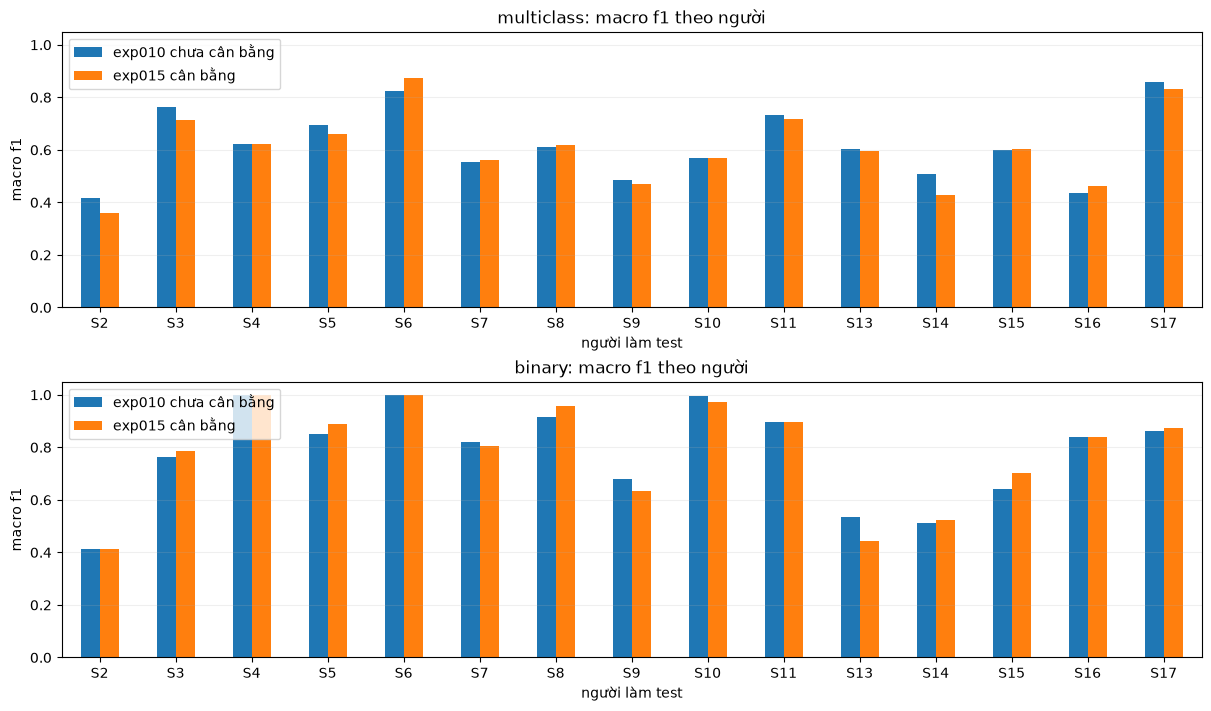

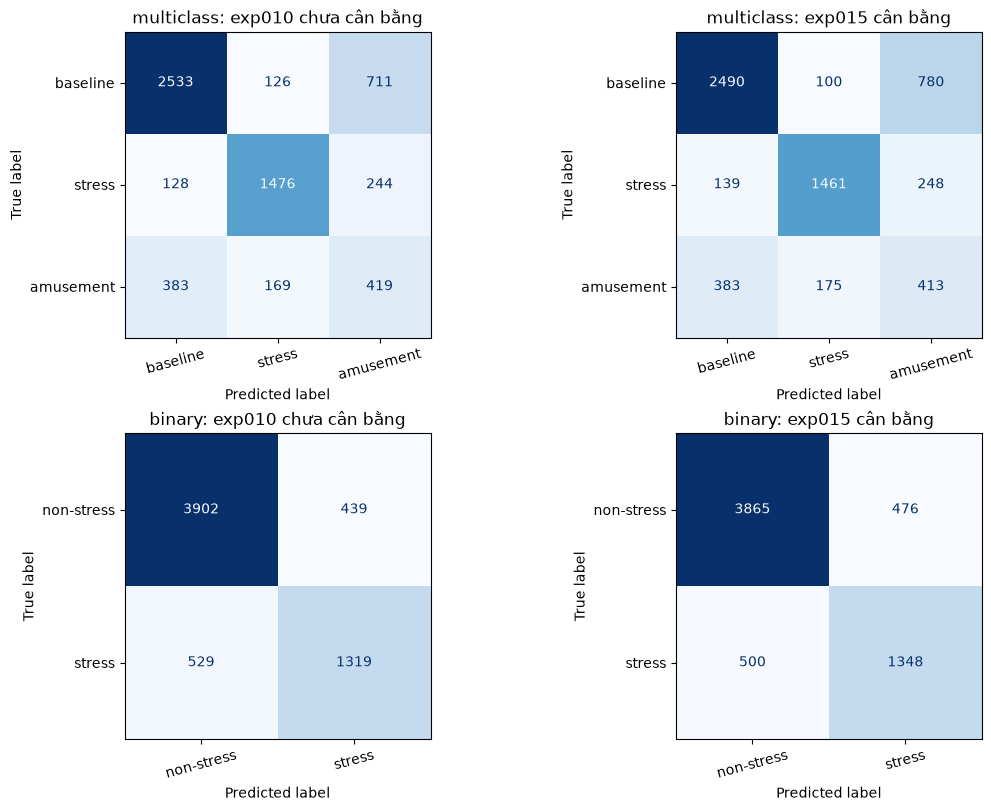

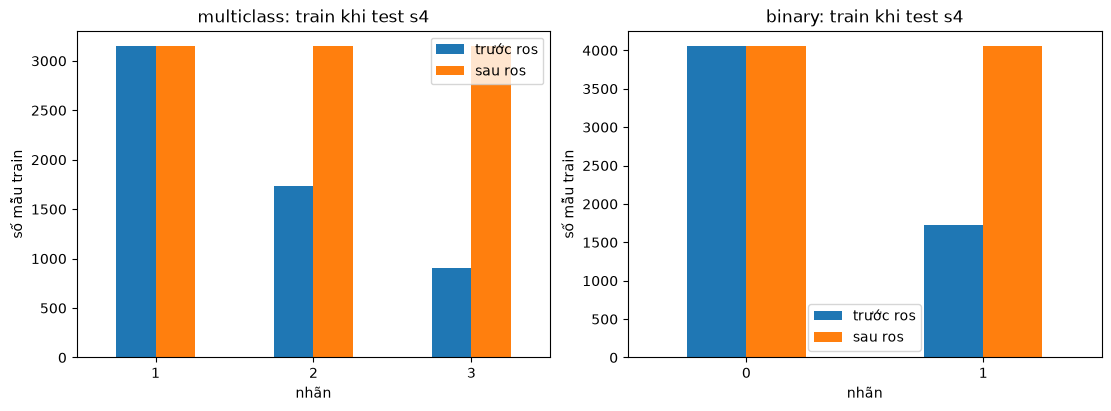

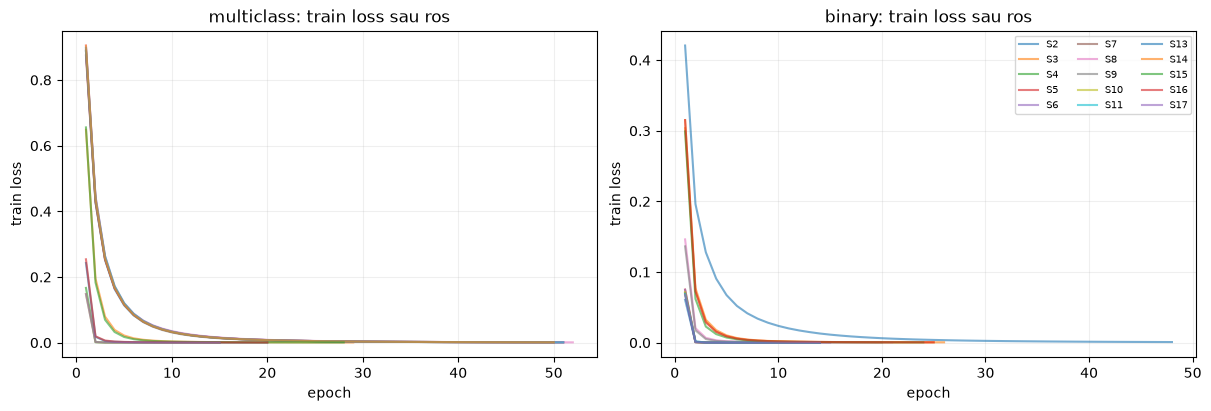

,task,subject_id,n_iter,train_loss,reached_max_iter,warning_count
0,multiclass,S2,51,0.000957,False,0
1,multiclass,S3,29,0.000677,False,0
2,multiclass,S4,15,0.000074,False,0
3,multiclass,S5,51,0.000959,False,0
4,multiclass,S6,51,0.001000,False,0
5,multiclass,S7,50,0.001023,False,0
6,multiclass,S8,52,0.000977,False,0
7,multiclass,S9,50,0.000953,False,0
8,multiclass,S10,15,0.000071,False,0
9,multiclass,S11,51,0.000955,False,0


In [12]:
if (run / 'folds').is_dir():
    losses = report.loss_traces(run)
else:
    losses = json.loads((run / 'loss_traces.json').read_text(encoding='utf-8'))
audit = pd.read_csv(run / 'sampler_audit.csv')
report.figures(run, paired, audit, losses)
display(convergence[['task', 'subject_id', 'n_iter', 'train_loss', 'reached_max_iter', 'warning_count']])


## 8. phân tích

nhận xét từ số đo thực tế

 giữ cả các người giảm điểm
 
 kiểm tra số mẫu test và nhãn thật khớp exp010
 
  audit chỉ dựng lại preprocessing/ros với cùng train và seed, chưa xuất sampler indices từ  pipeline đã train

In [13]:
conclusion = report.conclusion(run, comparison, convergence, audit)


## nhận xét — 16/11/2026

- binary: macro f1 cân bằng 0.7826 ± 0.1971; exp010 0.7819 ± 0.1869; tăng 0.0007. 7 người tăng, 5 người giảm, 3 người bằng nhau.
- multiclass: macro f1 cân bằng 0.6056 ± 0.1424; exp010 0.6187 ± 0.1338; giảm 0.0130. 5 người tăng, 9 người giảm, 1 người bằng nhau.

giữ đúng best_params của exp010 cho cả 30 outer folds; không tìm tham số lại.
30/30 kiểm tra sampler đạt; số mẫu test trước và sau bằng nhau.
có 0/30 lượt fit ghi cảnh báo; 0/30 lượt chạm max_iter=200.

cân bằng lớp không đảm bảo tăng macro f1 trên người mới. tham số ở đây được chọn cho pipeline chưa cân bằng; chưa kết luận đó là tham số tốt nhất cho pipeline có ros.

loss được tính trên train sau oversampling, không phải loss test. phân phối và số mẫu train đã đổi nên không diễn giải chênh lệch loss tuyệt đối với exp010 như bằng chứng cải thiện.

audit dựng lại preprocessing và sampler với đúng train và seed, không fit thêm mlp. runner chưa xuất sample_indices_ từ chính pipeline đã fit; đó là phần có 

## 9. nguồn gốc kết quả và nhật ký(18/11)

lưu data/config/source hash, environment, best_params, sampler audit, checkpoint và dự đoán

không nhận số đo cũ là lượt train mới 

In [14]:
print('data sha256:', config['data_sha256'])
print('source code sha256:', config['code_sha256'])
print('git commit lúc train:', config.get('git_commit'))
print('tham số đối chứng:', config['settings']['reference_params_sha256'])
print('dự đoán đối chứng:', config['settings']['reference_predictions_sha256'])
print('nguồn exp010:', report.REFERENCE)
print('nguồn exp015:', run)


data sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
source code sha256: 371dc95533c02a3fe749189ddb412a69e724cf77ca53782c0272715205a8dddf
git commit lúc train: None
tham số đối chứng: 1235ecbc2ba7495515765d43d6fd2183103b8193e723dd8b5ef9ed778e48356a
dự đoán đối chứng: 3d7acbd397f98504aa711c873b02630b9a690746c42764b25169d7b01b2a23d1
nguồn exp010: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\experiments\02_tuning\EXP-010\results
nguồn exp015: c:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\outputs\exp015_mlp_balanced_20261116_164228_806629


## 10. kiểm tra chạy lại — 18/11/2026

đã train độc lập thêm 2 lượt, cộng lượt gốc thành 3 lượt. mỗi lượt có 30 outer folds, tổng 90 lần fit

giữ cùng dữ liệu, best_params và seed 42 để kiểm tra khả năng tái lập; chưa đánh giá biến thiên giữa các seed



In [15]:
repeat_folder = root / 'experiments/03_balancing/EXP-015/results/repeatability'
display(pd.read_csv(repeat_folder / 'runs.csv'))
display(pd.read_csv(repeat_folder / 'scores.csv').round(4))
print(json.loads((repeat_folder / 'verification.json').read_text(encoding='utf-8')))
print('cùng seed để kiểm tra chạy lại, chưa phải kiểm tra độ ổn định qua nhiều seed')


,exp_chung,run_id,member,date,seed,outer_folds,predictions,prediction_differences,max_metric_difference,predictions_match,metrics_match,source_run
0,EXP-015,EXP-015-R01,như,16/11/2026,42,30,12378,0,0.0,True,True,experiments/03_balancing/EXP-015/results
1,EXP-015,EXP-015-R02,như,18/11/2026,42,30,12378,0,0.0,True,True,outputs/exp015_mlp_balanced_20261118_210644_00...
2,EXP-015,EXP-015-R03,như,18/11/2026,42,30,12378,0,0.0,True,True,outputs/exp015_mlp_balanced_20261118_210812_37...


,exp_chung,run_id,date,task,n_subjects,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std
0,EXP-015,EXP-015-R01,16/11/2026,binary,15,0.7826,0.1971,0.8085,0.1724
1,EXP-015,EXP-015-R01,16/11/2026,multiclass,15,0.6056,0.1424,0.6498,0.1137
2,EXP-015,EXP-015-R02,18/11/2026,binary,15,0.7826,0.1971,0.8085,0.1724
3,EXP-015,EXP-015-R02,18/11/2026,multiclass,15,0.6056,0.1424,0.6498,0.1137
4,EXP-015,EXP-015-R03,18/11/2026,binary,15,0.7826,0.1971,0.8085,0.1724
5,EXP-015,EXP-015-R03,18/11/2026,multiclass,15,0.6056,0.1424,0.6498,0.1137


{'status': 'passed', 'exp_chung': 'EXP-015', 'independent_training_runs': 3, 'total_outer_fits': 90, 'predictions_per_run': 12378, 'seed': 42, 'all_predictions_match': True, 'all_metrics_match': True, 'interpretation': 'same-seed reproducibility; not stability across different seeds'}
cùng seed để kiểm tra chạy lại, chưa phải kiểm tra độ ổn định qua nhiều seed


## bổ sung so sánh train và test — 18/11/2026

giữ cấu hình đã chốt và refit để lấy điểm train/test từ cùng mô hình

dự đoán test của 30 lượt refit khớp kết quả cũ

mỗi điểm trên trục ngang là một lượt loso: 14 người train, 1 người test.



,task,subject_id,train_macro_f1,test_macro_f1,macro_f1_gap
0,multiclass,S2,1.0,0.3612,0.6388
1,multiclass,S3,1.0,0.7129,0.2871
2,multiclass,S4,1.0,0.6241,0.3759
3,multiclass,S5,1.0,0.6592,0.3408
4,multiclass,S6,1.0,0.8742,0.1258
5,multiclass,S7,1.0,0.5608,0.4392
6,multiclass,S8,1.0,0.6167,0.3833
7,multiclass,S9,1.0,0.4696,0.5304
8,multiclass,S10,1.0,0.5679,0.4321
9,multiclass,S11,1.0,0.7159,0.2841


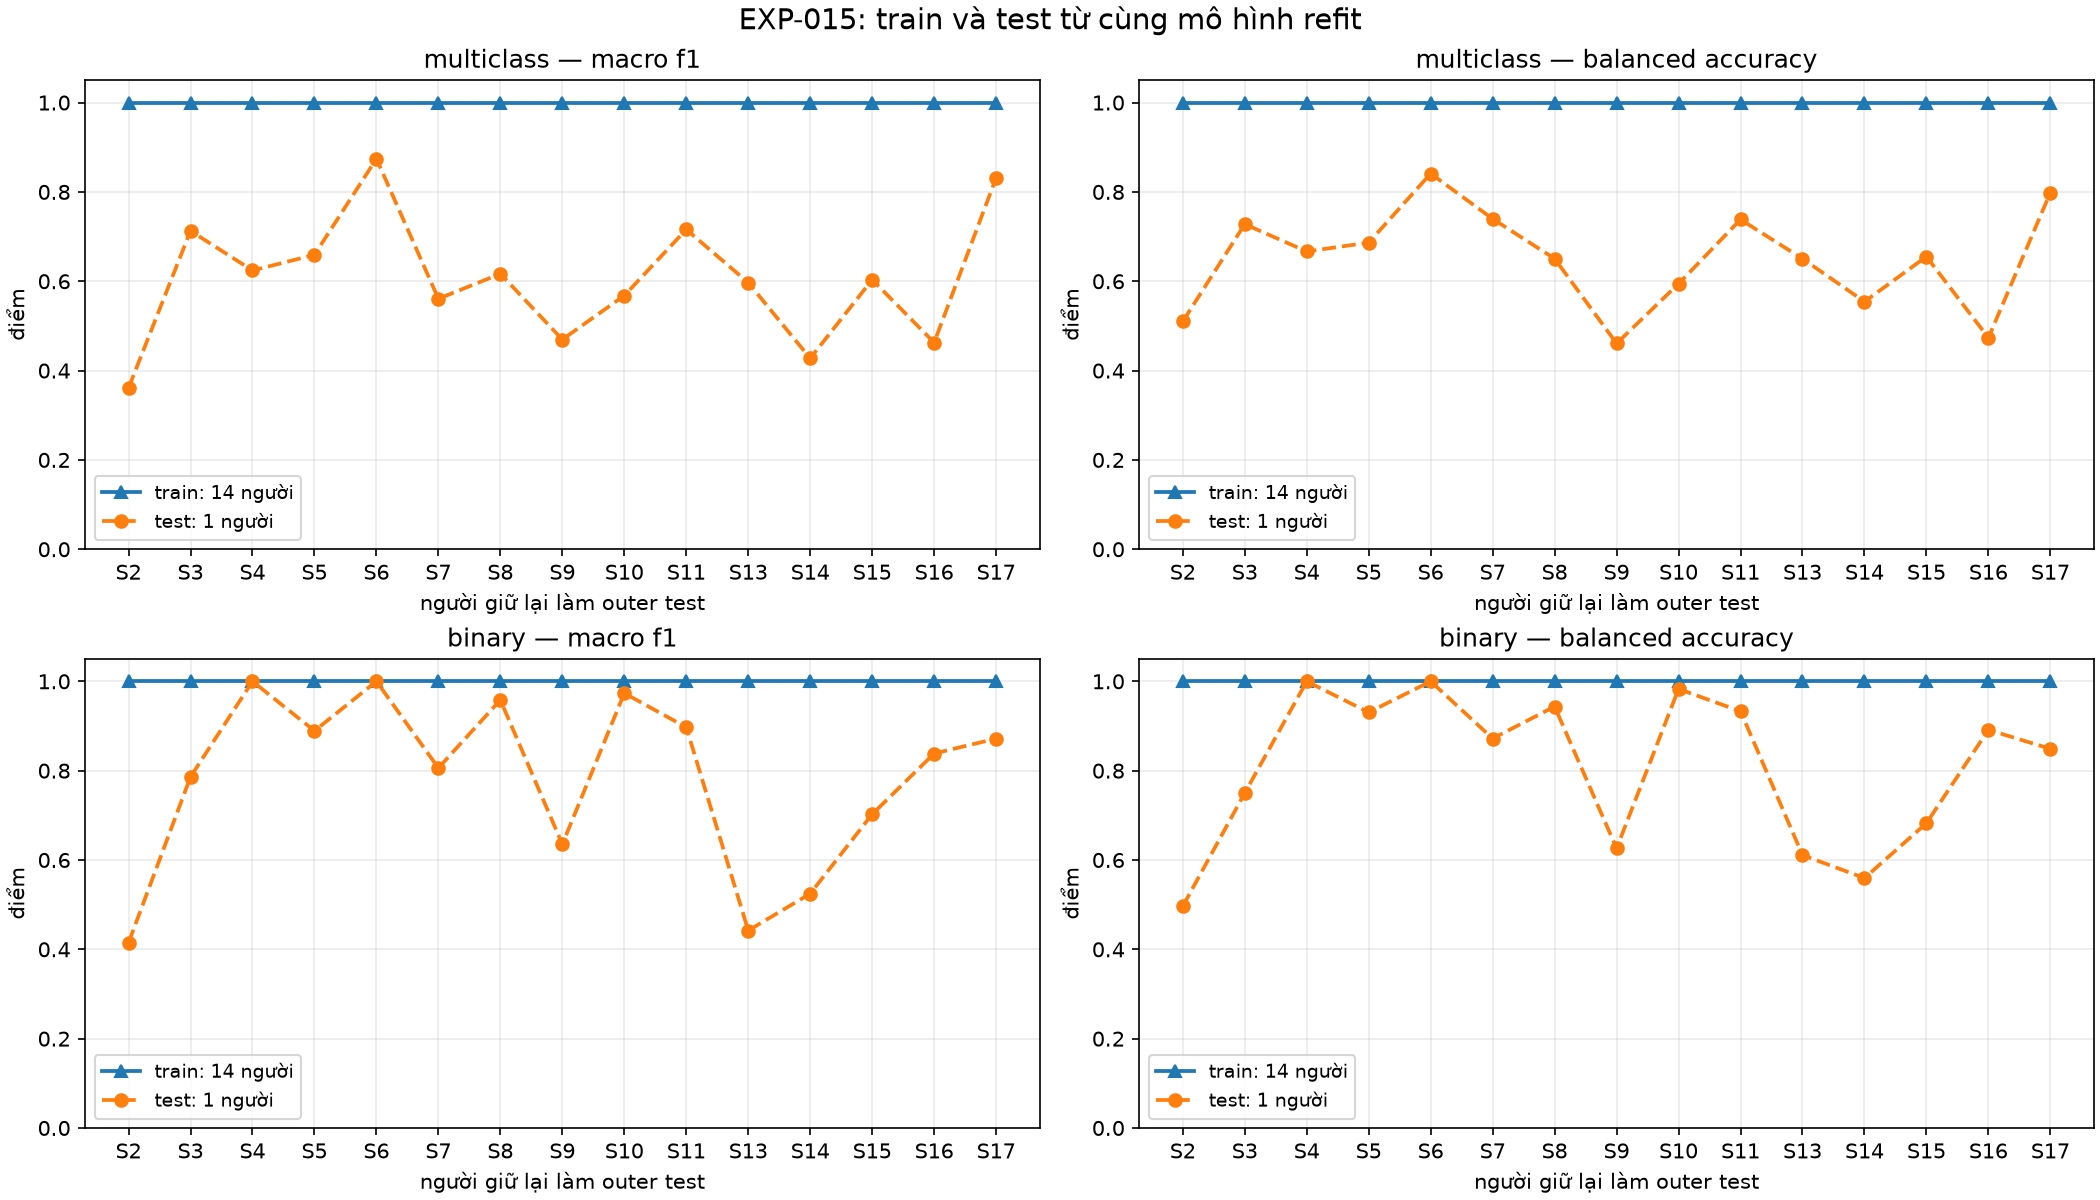

{'status': 'passed', 'outer_folds': 30, 'reference_predictions_match': True, 'reference_metrics_match': True, 'confusion_matrix_metrics_match': True, 'train_and_test_same_refitted_model': True, 'train_evaluated_before_ROS_duplication': True, 'test_not_used_for_model_selection': True}


In [17]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

diagnostic_candidates = [q for p in [Path.cwd(), *Path.cwd().parents]
                         for q in (p, p / "wesad-stress-detection")]
diagnostic_root = next(p for p in diagnostic_candidates
                       if (p / "src/wesad/evaluation.py").is_file())
diagnostic_folder = diagnostic_root / "experiments/03_balancing/EXP-015/results/train_test"
diagnostic_metrics = pd.read_csv(diagnostic_folder / "metrics.csv")
display(diagnostic_metrics[["task", "subject_id", "train_macro_f1",
                            "test_macro_f1", "macro_f1_gap"]].round(4))
display(Image(filename=str(diagnostic_folder / "train_vs_test.png")))
print(json.loads((diagnostic_folder / "verification.json").read_text(encoding="utf-8")))


# EXP-015: so sánh train và test — 18/11/2026

Đây là lượt refit bổ sung để đo cả train và test từ cùng mô hình và vẫn giữ  nguyên cấu hình đã chốt

Dự đoán test ở đủ 30 folds khớp toàn bộ kết quả đã lưu

 binary: macro f1 train 1.0000, test 0.7826; khoảng cách 0.2174
multiclass: macro f1 train 1.0000, test 0.6056; khoảng cách 0.3944

Mô hình khớp rất sát train nhưng điểm trên người chưa gặp thấp hơn ở nhiều folds.

=>Khoảng cách này cho thấy khả năng tổng quát hóa còn hạn chế

Trục ngang là người được giữ lại làm test, không phải epoch ,2 đường trên mỗi trục là điểm train và outer test

Điểm train tính trên các cửa sổ gốc của 14 người, kể cả ở exp015

Mean và độ lệch chuẩn mẫu theo 15 người. Các tập train giữa outer folds có chồng lặp nên không xem các điểm train là 15 quan sát độc lập để kiểm định.



## chạy thêm ngày 22/11/2026  seed 43 và 44

 Chạy mới seed 43/44, mỗi seed đủ 30 fold
 
 Câu hỏi: kết quả thay đổi bao nhiêu khi đổi seed? 

In [1]:
from pathlib import Path
import pandas as pd, json
root=next(p for p in [Path.cwd(),Path.cwd()/'wesad-stress-detection',*Path.cwd().parents] if (p/'src/wesad').is_dir())
folder=root/'experiments/03_balancing/EXP-015/seed_runs/20261122'
print('ngày chạy: 22/11/2026')
print(pd.read_csv(folder/'summary.csv').to_string(index=False))

ngày chạy: 22/11/2026
experiment       task  seed  subjects  macro_f1_mean  macro_f1_sd  ba_mean    ba_sd  train_f1  train_ba  epochs_mean  warnings  max_iter_folds
   EXP-015     binary    42        15       0.782632     0.197080 0.808506 0.172356       1.0       1.0    20.133333         0               0
   EXP-015     binary    43        15       0.862596     0.123312 0.869160 0.124528       1.0       1.0    24.533333         0               0
   EXP-015     binary    44        15       0.823493     0.176072 0.842171 0.158484       1.0       1.0    33.133333         0               0
   EXP-015 multiclass    42        15       0.605639     0.142448 0.649838 0.113676       1.0       1.0    36.533333         0               0
   EXP-015 multiclass    43        15       0.664549     0.125040 0.701984 0.117102       1.0       1.0    27.733333         0               0
   EXP-015 multiclass    44        15       0.589462     0.116076 0.632131 0.096027       1.0       1.0    33.000000    

Thanh sai số là SD giữa 15 người

Seed 42 của EXP010/015 đọc từ lượt chính cũ; điểm train của mốc này lấy từ refit đã kiểm tra khớp dự đoán test

 Các lượt mới đo train và test bằng cùng mô hình đang fit ,Train chấm trên cửa sổ gốc, trước nhân bản ROS

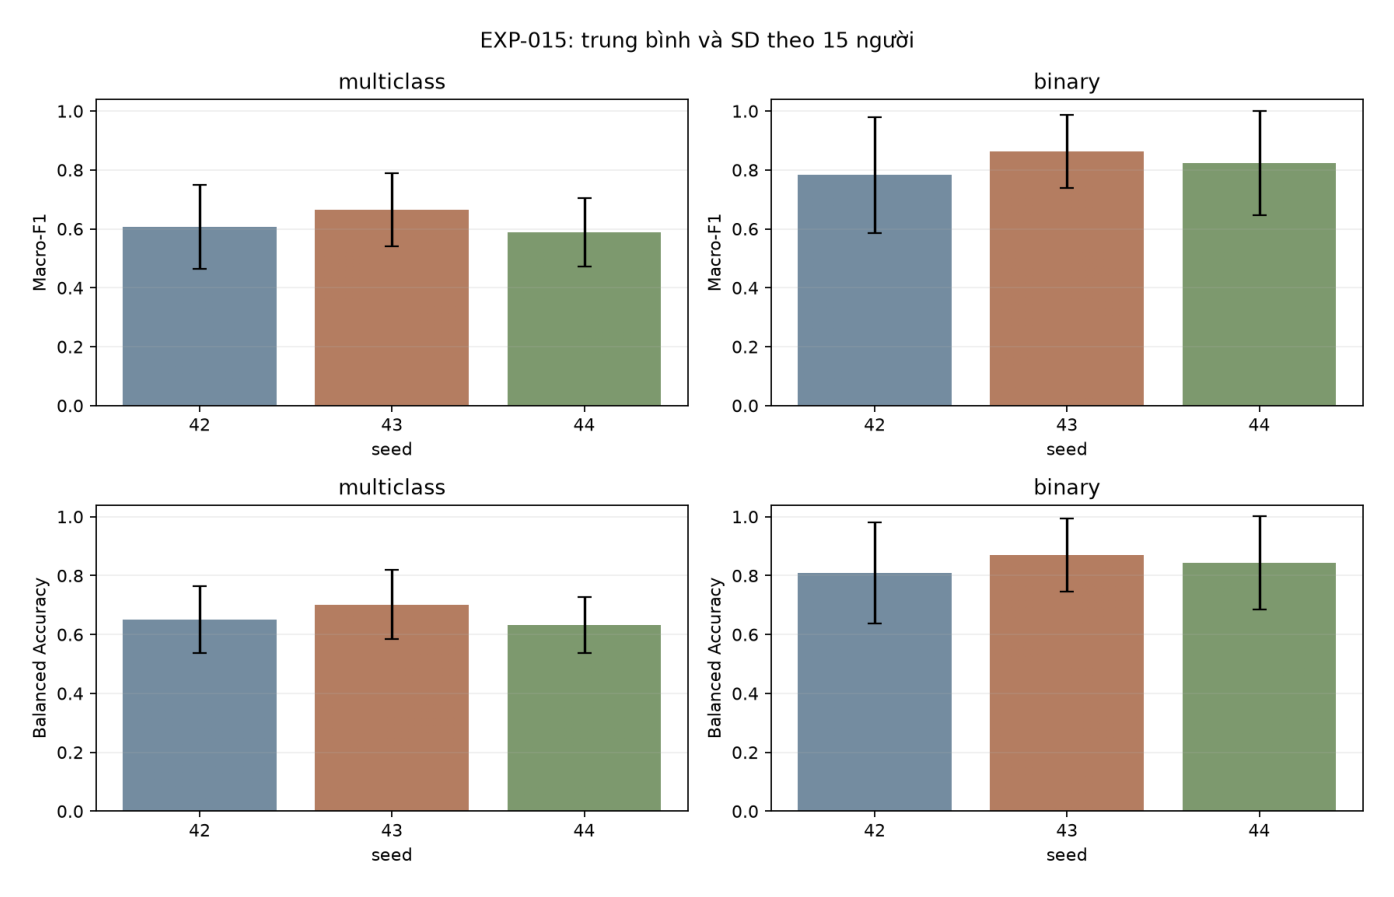

In [2]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(11,7))
plt.imshow(plt.imread(folder/'figures/scores.png'))
plt.axis('off')
fig.tight_layout()

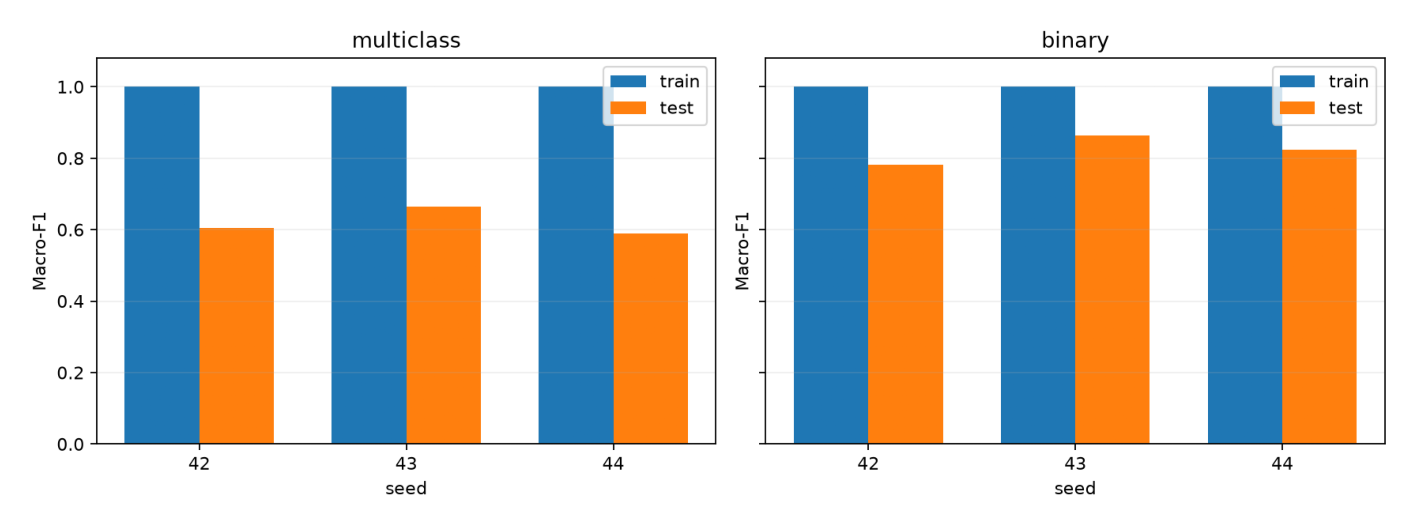

In [3]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(11,7))
plt.imshow(plt.imread(folder/'figures/train_test.png'))
plt.axis('off')
fig.tight_layout()

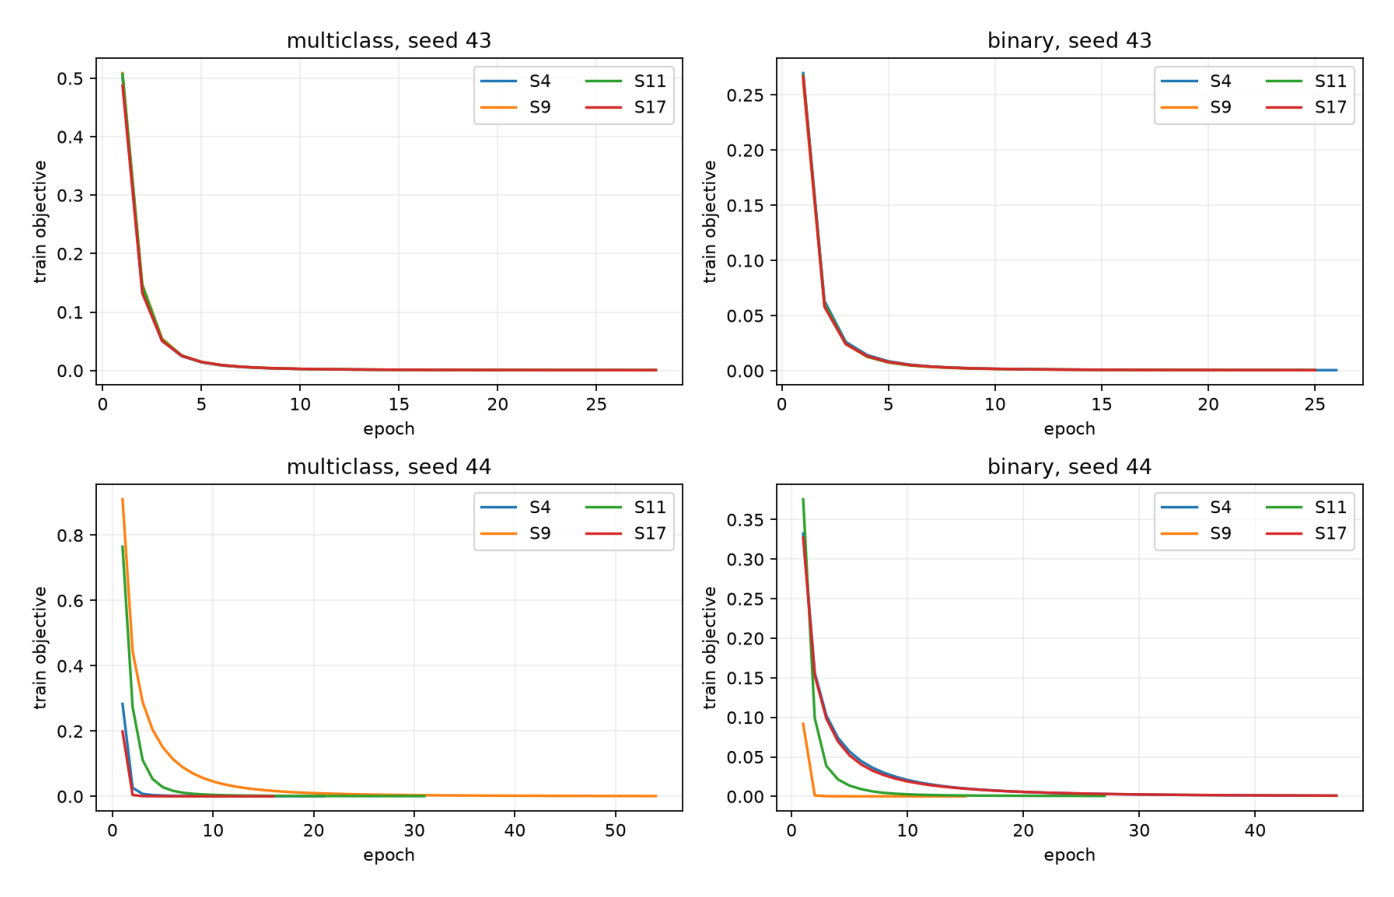

In [4]:
import matplotlib.pyplot as plt
fig=plt.figure(figsize=(11,7))
plt.imshow(plt.imread(folder/'figures/loss.png'))
plt.axis('off')
fig.tight_layout()

Loss là train objective, không phải loss test

Các fold có thể chọn alpha khác nhau  không dùng độ lớn loss để xếp hạng mô hình

In [5]:
events=[]
for seed in [43,44]:
    events.extend(json.loads(line) for line in (folder/f'seed_{seed}_journal.jsonl').read_text(encoding='utf8').splitlines())
print(pd.DataFrame(events).to_string(index=False))

      date member experiment  seed  status                         note
22/11/2026    như    EXP-015    43 bắt đầu chạy đủ 15 người, 2 bài toán
22/11/2026    như    EXP-015    43    xong     đủ 30 fold, kiểm tra đạt
22/11/2026    như    EXP-015    44 bắt đầu chạy đủ 15 người, 2 bài toán
22/11/2026    như    EXP-015    44    xong     đủ 30 fold, kiểm tra đạt
